# V6 · L40S 최종 모델 실험

XLS-R+AASIST LA + MERT95 + PANNs + HTDemucs + DF-Arena 원본 보조 + 시간 정렬 결합.
큰 모델은 고정하고 음악 분류층과 파일 결합기를 학습합니다. 실행 전 VESSL 값을 확인하세요.

실제 VESSL 환경에 Python 3.11 가상환경을 따로 만들어 학습합니다.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import json, os, signal, subprocess, sys, time, zipfile
ROOT = Path.cwd()
BUNDLE = ROOT / "V6_H100_RunBundle.zip"
PROJECT = ROOT / "V6_L40S"
PYTHON = sys.executable
# VESSL 화면에서 확인한 실제 값으로 입력합니다.
AVAILABLE_CREDIT_USD = 18.014171
GPU_USD_PER_HOUR = 1.80
VESSL_RESUMED_UTC = "2026-09-14T17:35:53.688312+00:00"  # 예: "2026-09-14T17:00:00+00:00"
COMPUTE_BUDGET_USD = 15.0
RESERVE_USD = 3.0
EPOCHS = 300
assert AVAILABLE_CREDIT_USD is not None and GPU_USD_PER_HOUR is not None
assert VESSL_RESUMED_UTC is not None and GPU_USD_PER_HOUR > 0
resumed = datetime.fromisoformat(VESSL_RESUMED_UTC)
assert resumed.tzinfo is not None
budget = min(COMPUTE_BUDGET_USD, AVAILABLE_CREDIT_USD - RESERVE_USD)
assert budget > 0, "실행 예산이 없습니다."
# 종료 후 확인 및 Pause에 쓸 15분을 제외합니다.
deadline_utc = resumed.timestamp() + min(4 * 3600, budget / GPU_USD_PER_HOUR * 3600) - 15 * 60
assert deadline_utc - time.time() > 600, "남은 실행 시간이 부족합니다."
print({"compute_budget_usd": budget, "hard_stop_utc": datetime.fromtimestamp(deadline_utc, timezone.utc).isoformat()})


{'compute_budget_usd': 15.0, 'hard_stop_utc': '2026-09-14T21:20:53.688312+00:00'}


## 1. 업로드 묶음 풀기
같은 폴더의 ZIP을 사용합니다. 이미 풀린 파일은 크기와 CRC를 확인한 뒤 재사용합니다.

In [2]:
import zlib
PROJECT.mkdir(exist_ok=True)
with zipfile.ZipFile(BUNDLE) as archive:
    for member in archive.infolist():
        target = (PROJECT / member.filename).resolve()
        assert target.is_relative_to(PROJECT.resolve()), "ZIP 경로 오류"
        if target.is_file() and target.stat().st_size == member.file_size:
            crc = 0
            with target.open("rb") as stream:
                while chunk := stream.read(8 * 1024 * 1024):
                    crc = zlib.crc32(chunk, crc)
            if crc & 0xffffffff == member.CRC:
                continue
        archive.extract(member, PROJECT)
print("압축 해제 완료:", PROJECT)


압축 해제 완료: /root/V6_L40S


## 2. 환경 설치와 GPU 확인
Torch·torchaudio·torchvision 버전을 함께 고정합니다. 학습은 새 프로세스로 실행하므로 설치 전 커널의 import 상태를 재사용하지 않습니다.

In [3]:
def run_bounded(command):
    remaining = deadline_utc - time.time()
    assert remaining > 30, "실행 시간 한도 도달"
    process = subprocess.Popen(command, cwd=PROJECT, start_new_session=True)
    try:
        code = process.wait(timeout=remaining)
    except subprocess.TimeoutExpired:
        os.killpg(process.pid, signal.SIGTERM)
        try:
            process.wait(timeout=20)
        except subprocess.TimeoutExpired:
            os.killpg(process.pid, signal.SIGKILL)
            process.wait()
        raise RuntimeError("시간 한도로 작업을 중단했습니다. VESSL도 Pause해야 과금이 멈춥니다.")
    assert code == 0, f"프로세스 실패: {code}"
run_bounded([sys.executable, "-m", "pip", "install", "uv==0.11.19"])
PYTHON = str(PROJECT / ".venv/bin/python")
if not Path(PYTHON).exists():
    run_bounded([sys.executable, "-m", "uv", "venv", "--seed", "--python", "3.11", str(PROJECT / ".venv")])
run_bounded([PYTHON, "-m", "pip", "install", "-r", "requirements.txt"])
run_bounded(["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv,noheader"])
run_bounded([PYTHON, "-c", "import torch,onnxruntime as o; assert torch.cuda.is_available(); assert 'CUDAExecutionProvider' in o.get_available_providers(); print(torch.__version__,o.__version__)"])


Looking in indexes: https://pypi.org/simple, https://download.pytorch.org/whl/cu128


NVIDIA L40S, 46068 MiB


2026-09-14 17:55:00.533299583 [W:onnxruntime:Default, device_discovery.cc:164 DiscoverDevicesForPlatform] GPU device discovery failed: device_discovery.cc:89 ReadFileContents Failed to open file: "/sys/class/drm/card0/device/vendor"


2.7.1+cu128 1.23.2


## 3. 원본 그룹 분할
음악 분류층과 파일 결합기를 서로 다른 원본으로 학습합니다. 기존 개발 평가 세트는 새 holdout으로 취급하지 않습니다.

In [4]:
run_bounded([PYTHON, "run_v6_final.py", "prepare", "--work", "v6_run"])
split = json.loads((PROJECT / "v6_run/split.json").read_text())
print({key: len(split[key]) for key in ("expert", "fusion", "dev")})


{'expert': 1137, 'fusion': 459, 'dev': 210}


{'expert': 1137, 'fusion': 459, 'dev': 210}


## 4. 특징 추출 → 300 epoch 학습 → 평가
25개 파일마다 로그를 남깁니다. 화면 확인은 15분 간격으로 하고, 오류·완료·시간 한도에 대응합니다. 캐시는 파일·모델·코드 해시가 일치할 때만 재사용합니다.

In [5]:
remaining_hours = (deadline_utc - time.time()) / 3600
run_bounded([PYTHON, "run_v6_final.py", "train", "--assets", "model/assets", "--work", "v6_run", "--device", "cuda", "--epochs", str(EPOCHS), "--max-hours", str(remaining_hours)])
metrics = json.loads((PROJECT / "v6_run/dev_metrics.json").read_text())
print(json.dumps(metrics, indent=2, ensure_ascii=False))


2026-09-14 17:55:22.231122540 [W:onnxruntime:Default, device_discovery.cc:164 DiscoverDevicesForPlatform] GPU device discovery failed: device_discovery.cc:89 ReadFileContents Failed to open file: "/sys/class/drm/card0/device/vendor"


2026-09-14 17:55:31.012248217 [W:onnxruntime:, transformer_memcpy.cc:111 ApplyImpl] 24 Memcpy nodes are added to the graph main_graph for CUDAExecutionProvider. It might have negative impact on performance (including unable to run CUDA graph). Set session_options.log_severity_level=1 to see the detail logs before this message.
2026-09-14 17:55:31.028095210 [W:onnxruntime:, session_state.cc:1316 VerifyEachNodeIsAssignedToAnEp] Some nodes were not assigned to the preferred execution providers which may or may not have an negative impact on performance. e.g. ORT explicitly assigns shape related ops to CPU to improve perf.
2026-09-14 17:55:31.028106320 [W:onnxruntime:, session_state.cc:1318 VerifyEachNodeIsAssignedToAnEp] Rerunning with verbose output on a non-minimal build will show node assignments.


2026-09-14 17:55:31.521477091 [W:onnxruntime:Default, scatter_nd.h:51 ScatterNDWithAtomicReduction] ScatterND with reduction=='none' only guarantees to be correct if indices are not duplicated.
2026-09-14 17:55:31.522656980 [W:onnxruntime:Default, scatter_nd.h:51 ScatterNDWithAtomicReduction] ScatterND with reduction=='none' only guarantees to be correct if indices are not duplicated.
2026-09-14 17:55:31.522680620 [W:onnxruntime:Default, scatter_nd.h:51 ScatterNDWithAtomicReduction] ScatterND with reduction=='none' only guarantees to be correct if indices are not duplicated.
2026-09-14 17:55:31.522699840 [W:onnxruntime:Default, scatter_nd.h:51 ScatterNDWithAtomicReduction] ScatterND with reduction=='none' only guarantees to be correct if indices are not duplicated.
2026-09-14 17:55:31.522716701 [W:onnxruntime:Default, scatter_nd.h:51 ScatterNDWithAtomicReduction] ScatterND with reduction=='none' only guarantees to be correct if indices are not duplicated.
2026-09-14 17:55:31.522779971 

Checkpoint path: /root/V6_L40S/model/assets/baseline/model/panns/Cnn14_mAP=0.431.pth


GPU number: 1


...

{"status": "extracting", "completed": 1775, "total": 1806, "elapsed_seconds": 3305.0}


{"status": "extracting", "completed": 1800, "total": 1806, "elapsed_seconds": 3312.0}


{"status": "extracting", "completed": 1806, "total": 1806, "elapsed_seconds": 3314.5}


{
  "status": "complete",
  "purpose": "final",
  "version": "v6-xlsraasist-la-mert95-aligned-1",
  "epochs_requested": 300,
  "epochs_completed": 300,
  "music_files": 823,
  "fusion_files": 459,
  "dev_files": 210,
  "asset_id": "b5da2bf48b57d9354312e532e579ec4765eb3c52fa335e10fc2f5845ad5b4f01",
  "cache_id": "4f231d18dcfcfb77cada135392d1a00fe929267e3ca3c1650d7cc8bfcafe59be",
  "heads_sha256": "2f4ec5ca22bbe6eb5e8c64719637b953fdf61f6fb61a4cbee597aea304cb605e",
  "split_sha256": "67e305fa468708424a867738cd2def96005b68fc6c406d0740683cbc6004711f",
  "seed": 41,
  "voice": "frozen pretrained XLS-R+AASIST LA; no new voice fine-tuning",
  "dev_status": "Previously used development set; not a new untouched holdout",
  "initial_loss": 0.6931473016738892,
  "final_loss": 0.041980113834142685
}


{
  "score": null,
  "metrics": {
    "file_eer": 0.3857142857142857,
    "voice_eer": 0.4291666666666667,
    "music_eer": 0.4828571428571429,
    "voice_presence_auc": null,
    "music_presence_auc": 0.9954411764705886
  },
  "invalid": {
    "voice_presence_auc": "both positive and negative labels are required"
  },
  "partial": {
    "voice_eer": "known subset only; unknown relevant labels: 110",
    "voice_presence_auc": "known subset only; unknown relevant labels: 90"
  },
  "counts": {
    "file_eer": 210,
    "voice_eer": 100,
    "music_eer": 170,
    "voice_presence_auc": 120,
    "music_presence_auc": 210
  },
  "unknown_counts": {
    "file_eer": 0,
    "voice_eer": 110,
    "music_eer": 0,
    "voice_presence_auc": 90,
    "music_presence_auc": 0
  },
  "coverage": {
    "file_eer": 1.0,
    "voice_eer": 0.47619047619047616,
    "music_eer": 1.0,
    "voice_presence_auc": 0.5714285714285714,
    "music_presence_auc": 1.0
  }
}


## 5. 학습 곡선과 제출 ZIP
완료된 가중치만 제출 ZIP에 포함합니다. 그림은 음악 분류층의 학습 loss이며, 리더보드 개선을 뜻하지 않습니다.

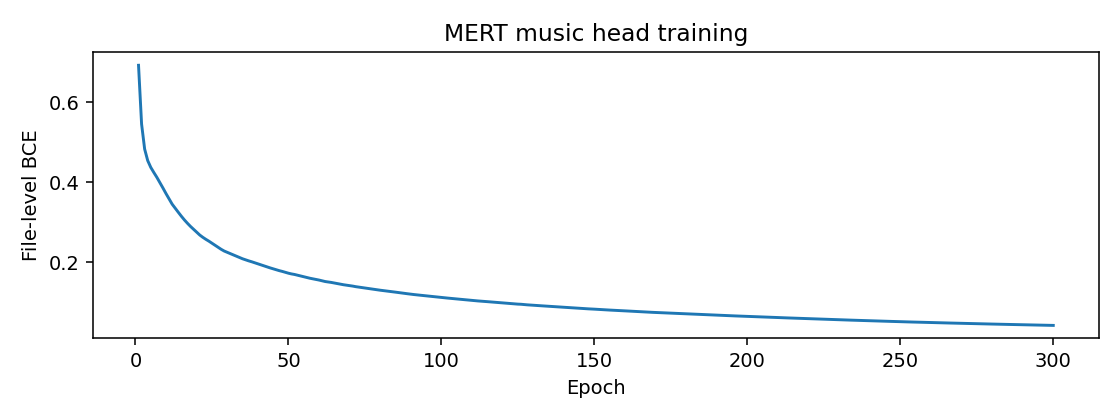

{
  "kind": "submission",
  "asset_id": "b5da2bf48b57d9354312e532e579ec4765eb3c52fa335e10fc2f5845ad5b4f01",
  "sha256": "d7f41cea68f04940fa815a4baa4d81378ad0bc0b87ce51468bd95587dabbf731",
  "bytes": 6005189474,
  "expanded_bytes": 6645859334,
  "members": 42,
  "trained": true,
  "target_gpu_runtime": "not verified by packaging"
}


완료. 결과와 이 노트북을 저장하고 VESSL 워크스페이스를 Pause하세요.


In [6]:
plot_code = """import json
import matplotlib.pyplot as plt
from pathlib import Path
losses=json.loads(Path('v6_run/losses.json').read_text())
plt.figure(figsize=(8,3));plt.plot(range(1,len(losses)+1),losses)
plt.xlabel('Epoch');plt.ylabel('File-level BCE');plt.title('MERT music head training')
plt.tight_layout();plt.savefig('v6_run/training_loss.png',dpi=140)
"""
run_bounded([PYTHON, "-c", plot_code])
from IPython.display import display, Image
display(Image(filename=str(PROJECT / "v6_run/training_loss.png")))
run_bounded([PYTHON, "package_v6_final.py", "--assets", "model/assets", "--work", "v6_run", "--output", "V6_final_submission.zip"])
print("완료. 결과와 이 노트북을 저장하고 VESSL 워크스페이스를 Pause하세요.")
